In [1]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_7/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Линейная модель для Tabular Playground Series (январь 2022)

Ноутбук основан на решении [AmbrosM](https://www.kaggle.com/ambrosm) для соревнования
[Tabular Playground Series - Jan 2022](https://www.kaggle.com/competitions/tabular-playground-series-jan-2022):
нужно спрогнозировать дневные продажи трёх товаров (`Kaggle Mug`, `Kaggle Hat`, `Kaggle Sticker`)
в двух магазинах (`KaggleMart`, `KaggleRama`) в трёх странах (Финляндия, Норвегия, Швеция).
Метрика соревнования — SMAPE.

В scikit-learn нет SMAPE в качестве функции потерь. Поэтому мы обучаем обычную линейную
регрессию (Ridge) на **преобразованном таргете** — логарифме продаж. У такого преобразования
несколько плюсов:
- MAE от логарифма хорошо приближает SMAPE. Почему? SMAPE — относительная ошибка, которую
  можно приблизить как `abs(y_pred - y_true) / y_true = abs(y_pred / y_true - 1)`. При малых
  ошибках `abs(y_pred / y_true - 1) ≈ abs(log(y_pred / y_true)) = abs(log(y_pred) - log(y_true))`,
  то есть MAE логарифмов. Относительная ошибка похожа на абсолютную ошибку логарифма таргета.
  На [графике](https://www.kaggle.com/c/tabular-playground-series-jan-2022/discussion/298473)
  этих двух функций разница почти незаметна.
- Регрессия может выдать отрицательный прогноз, а `exp(прогноз регрессии)` всегда положителен.
- С логарифмом таргета легко моделировать экспоненциальный рост.
- Большинство остальных эффектов тоже мультипликативные: продажи шапок в воскресенье
  в Финляндии = средние продажи шапок × «воскресный» множитель × «финский» множитель.

Работаем в **два этапа**:
1. Сначала строим простую модель без праздников. Графики её остатков помогают найти праздники.
2. Затем строим продвинутую модель с признаками для всех найденных праздников.

К решению есть [EDA-ноутбук](https://www.kaggle.com/ambrosm/tpsjan22-01-eda-which-makes-sense),
в котором визуализированы сезонные эффекты и различия в темпах роста.

In [2]:
import math
from datetime import date, datetime, timedelta

import dateutil.easter as easter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MaxNLocator
from scipy.stats import norm
from sklearn.linear_model import HuberRegressor, LinearRegression, Ridge  # noqa: F401
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

/Users/a.p.chikov/PycharmProjects/time-series-cu-2026/week_7/.venv/lib/python3.11/site-packages/joblib/_multiprocessing_helpers.py:44: UserWarning: [Errno 1] Operation not permitted.  joblib will operate in serial mode
  warnings.warn("%s.  joblib will operate in serial mode" % (e,))


Помимо данных соревнования используем внешний
[датасет с ВВП стран](https://www.kaggle.com/carlmcbrideellis/gdp-20152019-finland-norway-and-sweden)
за 2015–2019 годы: он хорошо объясняет различия в продажах между годами.

In [3]:
original_train_df = pd.read_csv("../data/tabular-playground-series-jan-2022/train.csv")
original_test_df = pd.read_csv("../data/tabular-playground-series-jan-2022/test.csv")
gdp_df = pd.read_csv(
    "../data/tabular-playground-series-jan-2022/GDP_data_2015_to_2019_Finland_Norway_Sweden.csv"
)

gdp_df.set_index("year", inplace=True)

# Даты читаются как строки, их нужно преобразовать
for df in [original_train_df, original_test_df]:
    df["date"] = pd.to_datetime(df.date)
original_train_df.head(2)

,row_id,date,country,store,product,num_sold
0,0,2015-01-01,Finland,KaggleMart,Kaggle Mug,329
1,1,2015-01-01,Finland,KaggleMart,Kaggle Hat,520


In [4]:
def smape_loss(y_true, y_pred):
    """SMAPE для каждого наблюдения (в процентах)."""
    return np.abs(y_true - y_pred) / (y_true + np.abs(y_pred)) * 200

# Простые признаки (без праздников)

В простой модели учитываем:
- страну, магазин и товар;
- день недели;
- сезонность для каждого товара — ряд Фурье с периодами 1 год и полгода;
- ВВП страны (его логарифм, так как мы прогнозируем логарифм таргета).

Остатки этой простой модели помогут понять, как влияют праздники.

In [5]:
def engineer(df):
    """Возвращает новый датафрейм с признаками."""

    def get_gdp(row):
        country = "GDP_" + row.country
        return gdp_df.loc[row.date.year, country]

    new_df = pd.DataFrame(
        {
            "gdp": np.log(df.apply(get_gdp, axis=1)),
            "wd4": df.date.dt.weekday == 4,  # пятница
            "wd56": df.date.dt.weekday >= 5,  # суббота и воскресенье
        }
    )

    # One-hot кодирование (последнюю категорию кодировать не нужно)
    for country in ["Finland", "Norway"]:
        new_df[country] = df.country == country
    new_df["KaggleRama"] = df.store == "KaggleRama"
    for product in ["Kaggle Mug", "Kaggle Hat"]:
        new_df[product] = df["product"] == product

    # Сезонность (ряд Фурье).
    # У трёх товаров разная сезонность, поэтому добавляем взаимодействия с товаром
    dayofyear = df.date.dt.dayofyear
    for k in range(1, 3):
        new_df[f"sin{k}"] = np.sin(dayofyear / 365 * 2 * math.pi * k)
        new_df[f"cos{k}"] = np.cos(dayofyear / 365 * 2 * math.pi * k)
        new_df[f"mug_sin{k}"] = new_df[f"sin{k}"] * new_df["Kaggle Mug"]
        new_df[f"mug_cos{k}"] = new_df[f"cos{k}"] * new_df["Kaggle Mug"]
        new_df[f"hat_sin{k}"] = new_df[f"sin{k}"] * new_df["Kaggle Hat"]
        new_df[f"hat_cos{k}"] = new_df[f"cos{k}"] * new_df["Kaggle Hat"]

    return new_df


train_df = engineer(original_train_df)
train_df["date"] = original_train_df.date
train_df["num_sold"] = original_train_df.num_sold.astype(np.float32)
test_df = engineer(original_test_df)

features = test_df.columns

for df in [train_df, test_df]:
    df[features] = df[features].astype(np.float32)
print(list(features))

['gdp', 'wd4', 'wd56', 'Finland', 'Norway', 'KaggleRama', 'Kaggle Mug', 'Kaggle Hat', 'sin1', 'cos1', 'mug_sin1', 'mug_cos1', 'hat_sin1', 'hat_cos1', 'sin2', 'cos2', 'mug_sin2', 'mug_cos2', 'hat_sin2', 'hat_cos2']


# Обучение простой модели (без праздников)

Обучаем модель на всех тренировочных данных. Кросс-валидацией займёмся позже — сначала
хотим посмотреть на графики остатков.

Для быстрой проверки строим прогноз для комбинации
`country='Norway', store='KaggleMart', product='Kaggle Hat'`.

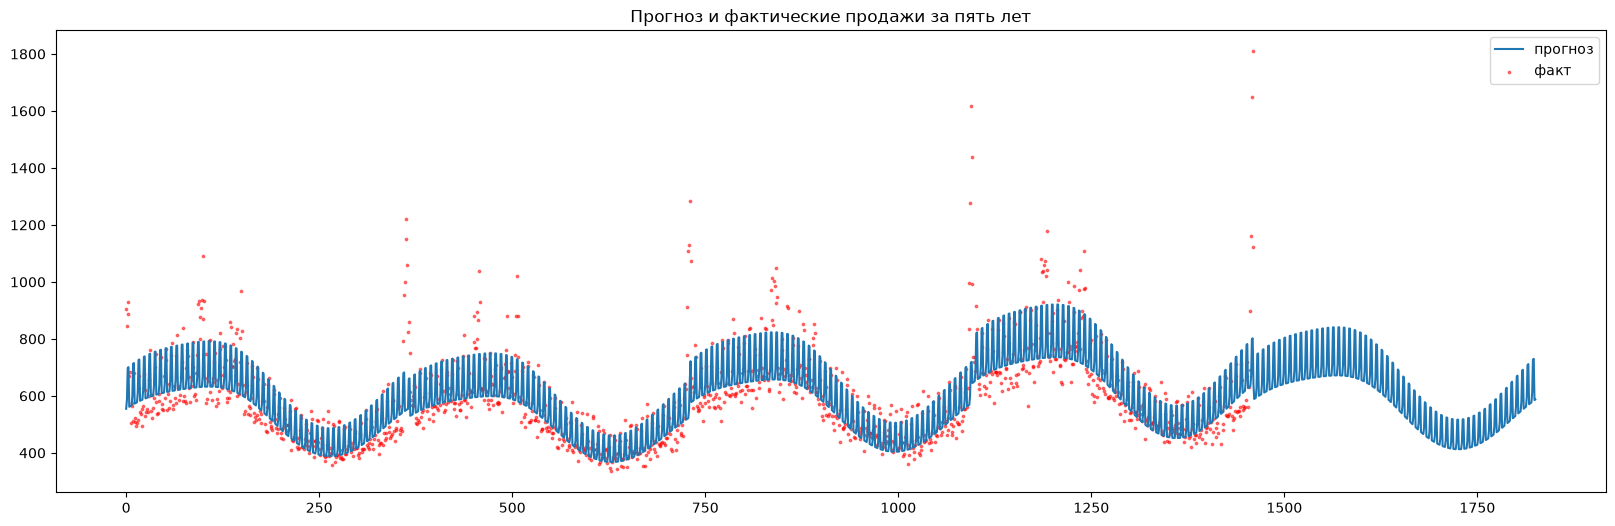

In [6]:
def fit_model(X_tr, X_va=None, fold=None):
    """Масштабирует данные, обучает модель и (если передана валидация) оценивает её."""
    start_time = datetime.now()

    # Предобработка данных
    X_tr_f = X_tr[features]
    preproc = StandardScaler()
    X_tr_f = preproc.fit_transform(X_tr_f)
    y_tr = X_tr.num_sold.values.reshape(-1, 1)

    # Обучение модели на логарифме таргета.
    # Можно попробовать и другие модели:
    # model = LinearRegression()
    # model = HuberRegressor(epsilon=1.20, max_iter=500)
    model = Ridge()
    model.fit(X_tr_f, np.log(y_tr).ravel())

    if X_va is not None:
        # Предобработка валидационных данных
        X_va_f = X_va[features]
        X_va_f = preproc.transform(X_va_f)
        y_va = X_va.num_sold.values.reshape(-1, 1)

        # Прогноз на валидации
        y_va_pred = np.exp(model.predict(X_va_f)).reshape(-1, 1)
        oof.update(pd.Series(y_va_pred.ravel(), index=X_va.index))

        # Оценка: время обучения и SMAPE
        smape = np.mean(smape_loss(y_va, y_va_pred))
        print(
            f"Фолд {fold} | {str(datetime.now() - start_time)[-12:-7]}"
            f" | SMAPE: {smape:.5f}"
        )
        score_list.append(smape)

        # График y_true vs. y_pred
        if fold == 0:
            plt.figure(figsize=(10, 10))
            plt.scatter(y_va, y_va_pred, s=1, color="r")
            plt.plot(
                [plt.xlim()[0], plt.xlim()[1]],
                [plt.xlim()[0], plt.xlim()[1]],
                "--",
                color="k",
            )
            plt.gca().set_aspect("equal")
            plt.xlabel("y_true")
            plt.ylabel("y_pred")
            plt.title("OOF-прогнозы")
            plt.show()

    return preproc, model


preproc, model = fit_model(train_df)


# Прогноз и факт за пять лет для одной комбинации страна–магазин–товар
def plot_five_years_combination(
    engineer, country="Norway", store="KaggleMart", product="Kaggle Hat"
):
    demo_df = pd.DataFrame(
        {
            "row_id": 0,
            "date": pd.date_range("2015-01-01", "2019-12-31", freq="D"),
            "country": country,
            "store": store,
            "product": product,
        }
    )
    demo_df.set_index("date", inplace=True, drop=False)
    demo_df = engineer(demo_df)
    demo_df["num_sold"] = np.exp(model.predict(preproc.transform(demo_df[features])))
    plt.figure(figsize=(20, 6))
    plt.plot(np.arange(len(demo_df)), demo_df.num_sold, label="прогноз")
    train_subset = train_df[
        (original_train_df.country == country)
        & (original_train_df.store == store)
        & (original_train_df["product"] == product)
    ]
    plt.scatter(
        np.arange(len(train_subset)),
        train_subset.num_sold,
        label="факт",
        alpha=0.5,
        color="red",
        s=3,
    )
    plt.legend()
    plt.title("Прогноз и фактические продажи за пять лет")
    plt.show()


plot_five_years_combination(engineer)

# Остатки простой модели

Построим остатки простой модели (SMAPE суммарных продаж за день). По графикам видно,
где находятся праздники:
- пик в конце года;
- три плавающих праздника, зависящих от полнолуния (Пасха);
- первая и вторая половины мая;
- начало и конец июня;
- начало ноября.

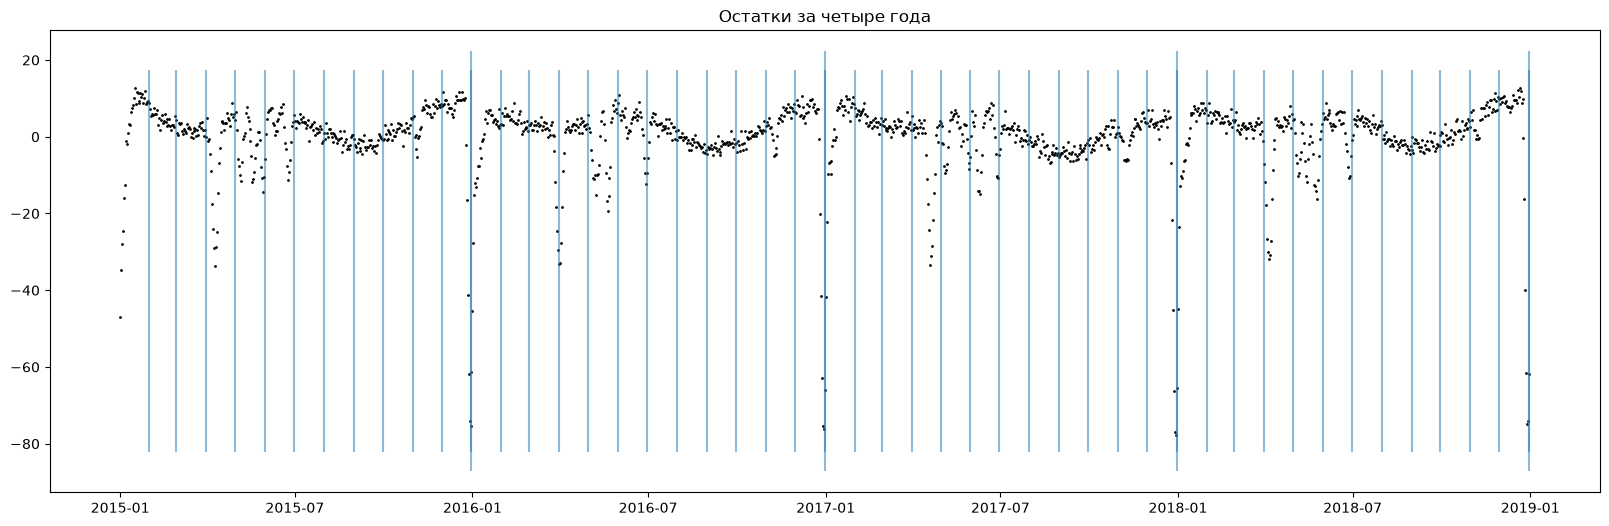

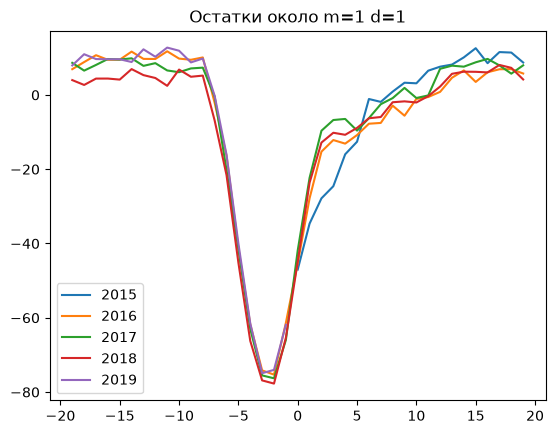

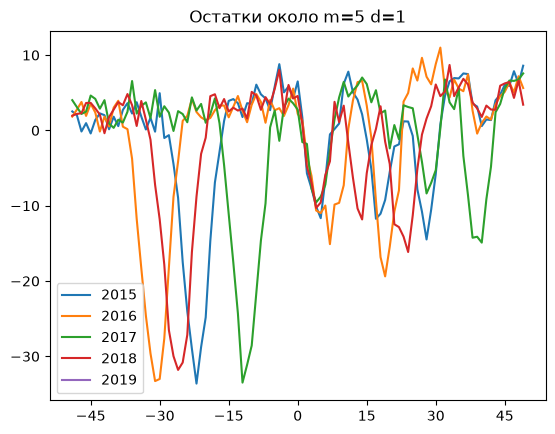

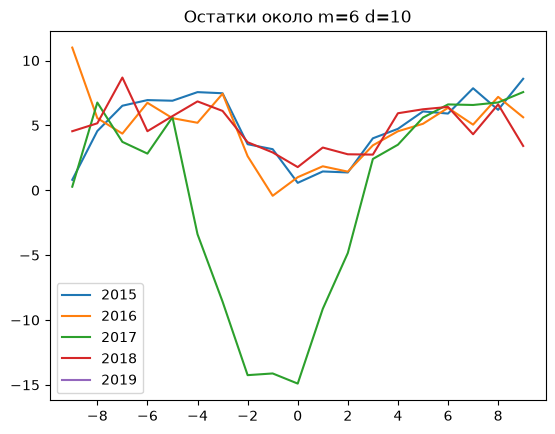

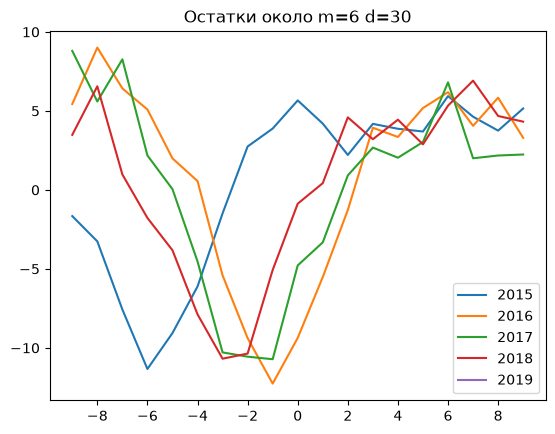

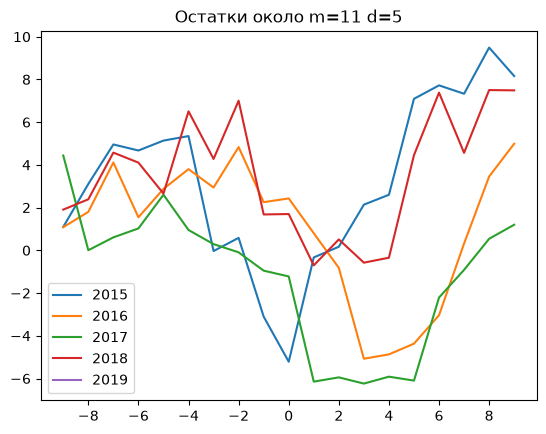

In [7]:
train_df["pred"] = np.exp(model.predict(preproc.transform(train_df[features])))
by_date = train_df.groupby(train_df["date"])
residuals = (
    (by_date.pred.sum() - by_date.num_sold.sum())
    / (by_date.pred.sum() + by_date.num_sold.sum())
    * 200
)


# Все остатки за четыре года (сумма по всем товарам)
def plot_all_residuals(residuals):
    plt.figure(figsize=(20, 6))
    plt.scatter(residuals.index, residuals, s=1, color="k")
    plt.vlines(
        pd.date_range("2015-01-01", "2019-01-01", freq="ME"),
        plt.ylim()[0],
        plt.ylim()[1],
        alpha=0.5,
    )
    plt.vlines(
        pd.date_range("2015-01-01", "2019-01-01", freq="YE"),
        plt.ylim()[0],
        plt.ylim()[1],
        alpha=0.5,
    )
    plt.title("Остатки за четыре года")
    plt.show()


plot_all_residuals(residuals)


# Остатки в интересных интервалах
def plot_around(residuals, m, d, w):
    """Остатки в окне шириной 2*w вокруг месяца m и дня d для каждого года."""
    plt.figure()
    plt.title(f"Остатки около m={m} d={d}")
    for y in np.arange(2015, 2020):
        d0 = pd.Timestamp(date(y, m, d))
        residual_range = residuals[
            (residuals.index > d0 - timedelta(w)) & (residuals.index < d0 + timedelta(w))
        ]
        plt.plot(
            [(r - d0).days for r in residual_range.index], residual_range, label=str(y)
        )
    plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))  # только целые подписи
    plt.legend()
    plt.show()


plot_around(residuals, 1, 1, 20)  # пик в конце года
plot_around(residuals, 5, 1, 50)  # три плавающих пика, зависящих от Пасхи
plot_around(residuals, 6, 10, 10)  # первая половина июня (в 2017 году накладывается Троица)
plot_around(residuals, 6, 30, 10)  # плавающий пик в конце июня
plot_around(residuals, 11, 5, 10)  # плавающий пик в начале ноября

# Дополнительные признаки (продвинутая модель)

По графикам остатков добавляем индикаторы праздников:
- отдельные дни конца декабря и начала января (общие и для каждой страны);
- дни мая (общие и норвежские);
- июньские дни в Швеции;
- дни вокруг последней среды июня (Финляндия и Швеция);
- дни после первого воскресенья ноября (Финляндия и Швеция);
- дни после 6 декабря (День независимости Финляндии);
- дни относительно Пасхи: вокруг самой Пасхи, после Вознесения (+39 дней) и после
  Троицы (+49 дней).

In [8]:
def engineer_more(df):
    """Возвращает новый датафрейм с расширенным набором признаков."""
    new_df = engineer(df)

    # Конец года
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"dec{d}": (df.date.dt.month == 12) & (df.date.dt.day == d)
                    for d in range(24, 32)
                }
            ),
            pd.DataFrame(
                {
                    f"n-dec{d}": (df.date.dt.month == 12)
                    & (df.date.dt.day == d)
                    & (df.country == "Norway")
                    for d in range(24, 32)
                }
            ),
            pd.DataFrame(
                {
                    f"f-jan{d}": (df.date.dt.month == 1)
                    & (df.date.dt.day == d)
                    & (df.country == "Finland")
                    for d in range(1, 14)
                }
            ),
            pd.DataFrame(
                {
                    f"jan{d}": (df.date.dt.month == 1)
                    & (df.date.dt.day == d)
                    & (df.country == "Norway")
                    for d in range(1, 10)
                }
            ),
            pd.DataFrame(
                {
                    f"s-jan{d}": (df.date.dt.month == 1)
                    & (df.date.dt.day == d)
                    & (df.country == "Sweden")
                    for d in range(1, 15)
                }
            ),
        ],
        axis=1,
    )

    # Май
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"may{d}": (df.date.dt.month == 5) & (df.date.dt.day == d)
                    for d in range(1, 10)
                }
            ),
            pd.DataFrame(
                {
                    f"may{d}": (df.date.dt.month == 5)
                    & (df.date.dt.day == d)
                    & (df.country == "Norway")
                    for d in range(19, 26)
                }
            ),
        ],
        axis=1,
    )

    # Июнь
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"june{d}": (df.date.dt.month == 6)
                    & (df.date.dt.day == d)
                    & (df.country == "Sweden")
                    for d in range(8, 14)
                }
            ),
        ],
        axis=1,
    )

    # Последняя среда июня
    wed_june_date = df.date.dt.year.map(
        {
            2015: pd.Timestamp("2015-06-24"),
            2016: pd.Timestamp("2016-06-29"),
            2017: pd.Timestamp("2017-06-28"),
            2018: pd.Timestamp("2018-06-27"),
            2019: pd.Timestamp("2019-06-26"),
        }
    )
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"wed_june{d}": (df.date - wed_june_date == np.timedelta64(d, "D"))
                    & (df.country != "Norway")
                    for d in range(-4, 6)
                }
            ),
        ],
        axis=1,
    )

    # Первое воскресенье ноября
    sun_nov_date = df.date.dt.year.map(
        {
            2015: pd.Timestamp("2015-11-1"),
            2016: pd.Timestamp("2016-11-6"),
            2017: pd.Timestamp("2017-11-5"),
            2018: pd.Timestamp("2018-11-4"),
            2019: pd.Timestamp("2019-11-3"),
        }
    )
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"sun_nov{d}": (df.date - sun_nov_date == np.timedelta64(d, "D"))
                    & (df.country != "Norway")
                    for d in range(0, 9)
                }
            ),
        ],
        axis=1,
    )

    # Первая половина декабря (День независимости Финляндии, 6 декабря)
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"dec{d}": (df.date.dt.month == 12)
                    & (df.date.dt.day == d)
                    & (df.country == "Finland")
                    for d in range(6, 14)
                }
            ),
        ],
        axis=1,
    )

    # Пасха
    easter_date = df.date.apply(lambda date: pd.Timestamp(easter.easter(date.year)))
    new_df = pd.concat(
        [
            new_df,
            pd.DataFrame(
                {
                    f"easter{d}": (df.date - easter_date == np.timedelta64(d, "D"))
                    for d in list(range(-2, 11)) + list(range(40, 48)) + list(range(50, 59))
                }
            ),
        ],
        axis=1,
    )

    return new_df.astype(np.float32)


train_df = engineer_more(original_train_df)
train_df["date"] = original_train_df.date
train_df["num_sold"] = original_train_df.num_sold.astype(np.float32)
test_df = engineer_more(original_test_df)

features = list(test_df.columns)
print(list(features))

['gdp', 'wd4', 'wd56', 'Finland', 'Norway', 'KaggleRama', 'Kaggle Mug', 'Kaggle Hat', 'sin1', 'cos1', 'mug_sin1', 'mug_cos1', 'hat_sin1', 'hat_cos1', 'sin2', 'cos2', 'mug_sin2', 'mug_cos2', 'hat_sin2', 'hat_cos2', 'dec24', 'dec25', 'dec26', 'dec27', 'dec28', 'dec29', 'dec30', 'dec31', 'n-dec24', 'n-dec25', 'n-dec26', 'n-dec27', 'n-dec28', 'n-dec29', 'n-dec30', 'n-dec31', 'f-jan1', 'f-jan2', 'f-jan3', 'f-jan4', 'f-jan5', 'f-jan6', 'f-jan7', 'f-jan8', 'f-jan9', 'f-jan10', 'f-jan11', 'f-jan12', 'f-jan13', 'jan1', 'jan2', 'jan3', 'jan4', 'jan5', 'jan6', 'jan7', 'jan8', 'jan9', 's-jan1', 's-jan2', 's-jan3', 's-jan4', 's-jan5', 's-jan6', 's-jan7', 's-jan8', 's-jan9', 's-jan10', 's-jan11', 's-jan12', 's-jan13', 's-jan14', 'may1', 'may2', 'may3', 'may4', 'may5', 'may6', 'may7', 'may8', 'may9', 'may19', 'may20', 'may21', 'may22', 'may23', 'may24', 'may25', 'june8', 'june9', 'june10', 'june11', 'june12', 'june13', 'wed_june-4', 'wed_june-3', 'wed_june-2', 'wed_june-1', 'wed_june0', 'wed_june1', 

# Остатки продвинутой модели

Графики показывают, что остатки стали заметно меньше и что самые важные праздники
учтены правильно.

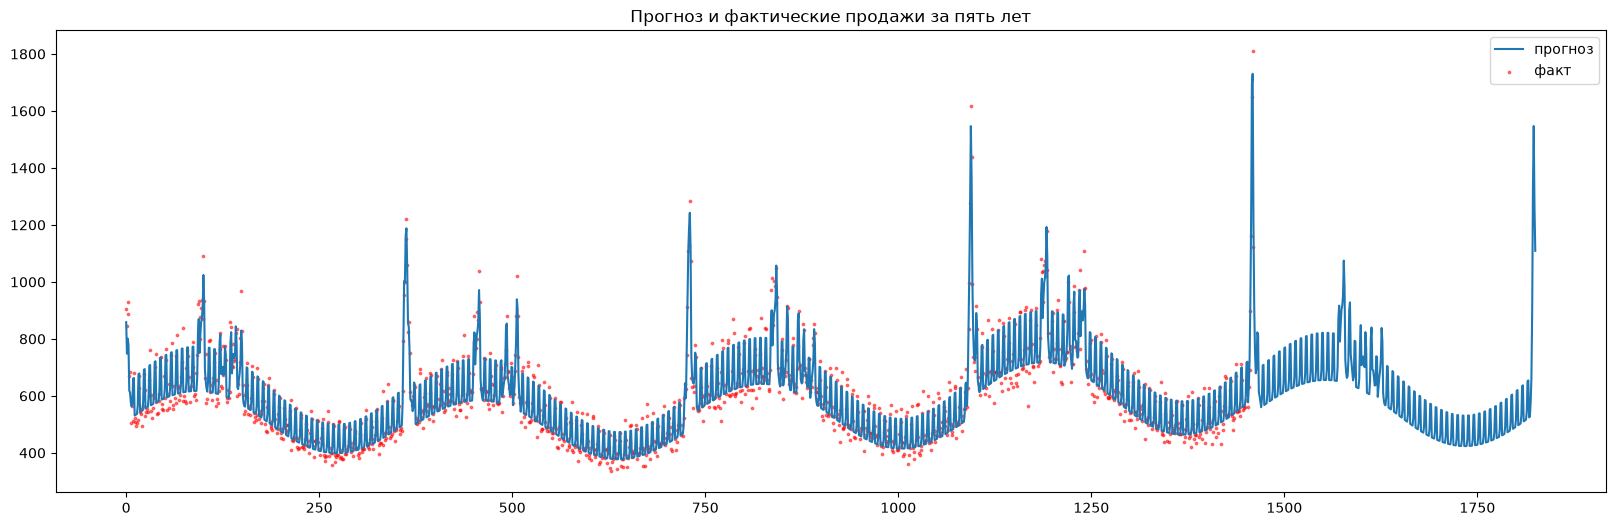

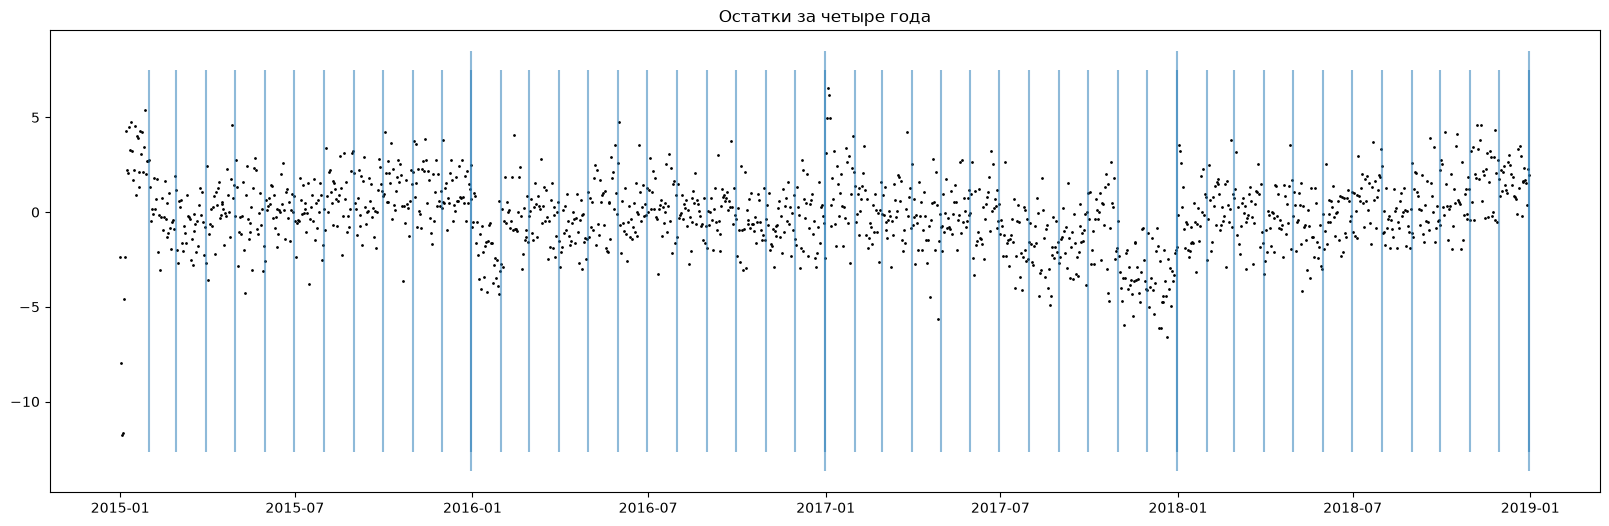

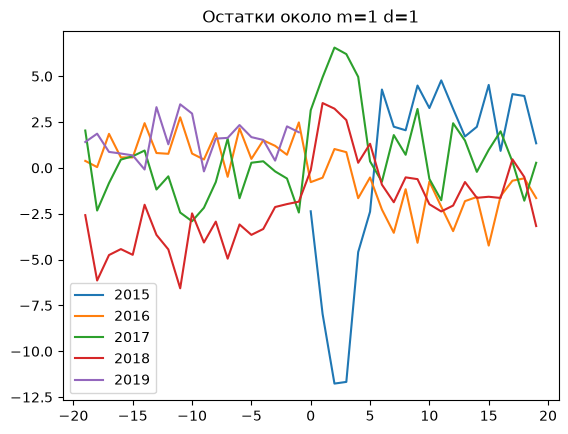

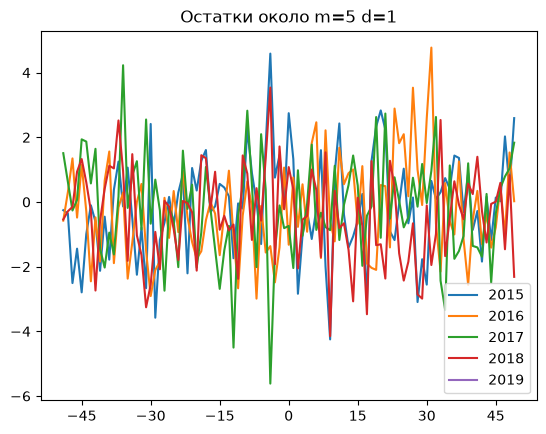

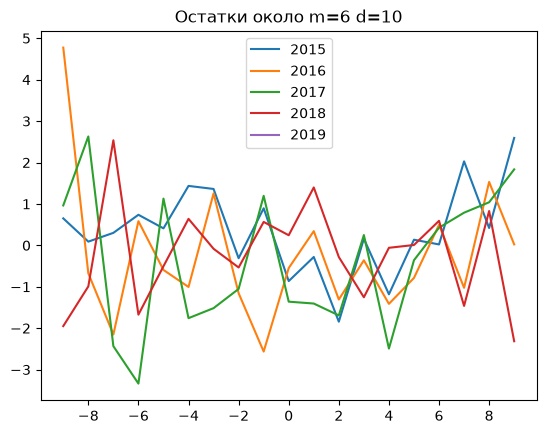

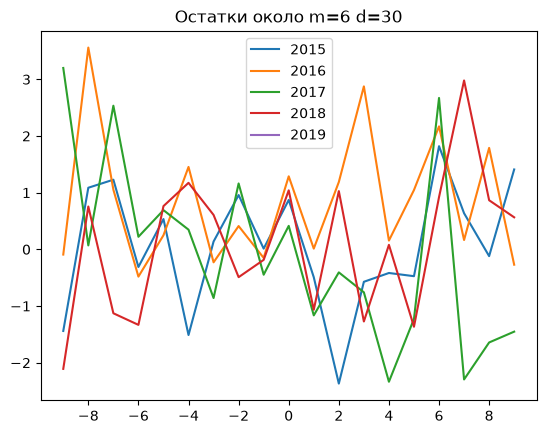

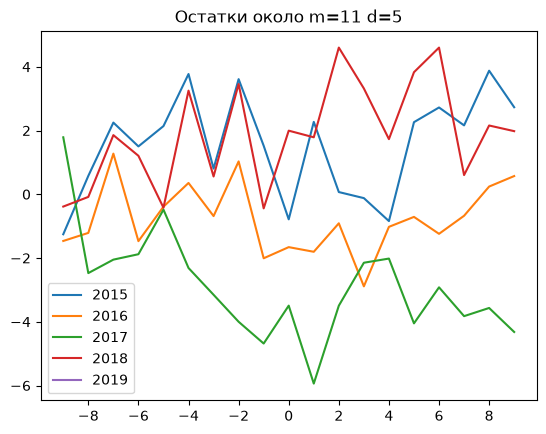

In [9]:
preproc, model = fit_model(train_df)
train_df["pred"] = np.exp(model.predict(preproc.transform(train_df[features])))
by_date = train_df.groupby(train_df["date"])
residuals = (
    (by_date.pred.sum() - by_date.num_sold.sum())
    / (by_date.pred.sum() + by_date.num_sold.sum())
    * 200
)

# Прогноз и факт за пять лет для одной комбинации страна–магазин–товар
plot_five_years_combination(engineer_more)

# Все остатки за четыре года (сумма по всем товарам)
plot_all_residuals(residuals)

# Остатки в интересных интервалах
plot_around(residuals, 1, 1, 20)  # пик в конце года
plot_around(residuals, 5, 1, 50)  # три плавающих пика, зависящих от Пасхи
plot_around(residuals, 6, 10, 10)  # первая половина июня (в 2017 году накладывается Троица)
plot_around(residuals, 6, 30, 10)  # плавающий пик в конце июня
plot_around(residuals, 11, 5, 10)  # плавающий пик в начале ноября

# Систематический анализ остатков

Графики остатков помогли продвинуться довольно далеко, но этого недостаточно. Проведём
более систематический анализ. Сначала посчитаем все остатки, на этот раз как разность
логарифма прогноза и логарифма факта.

Видно, что остатки распределены примерно нормально с центром в 0 и стандартным
отклонением около 0.053.

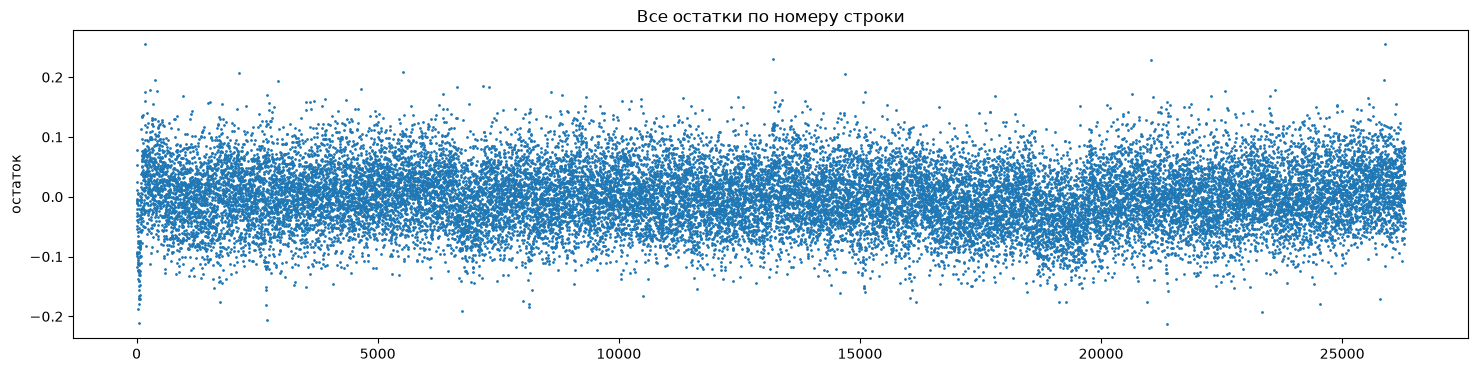

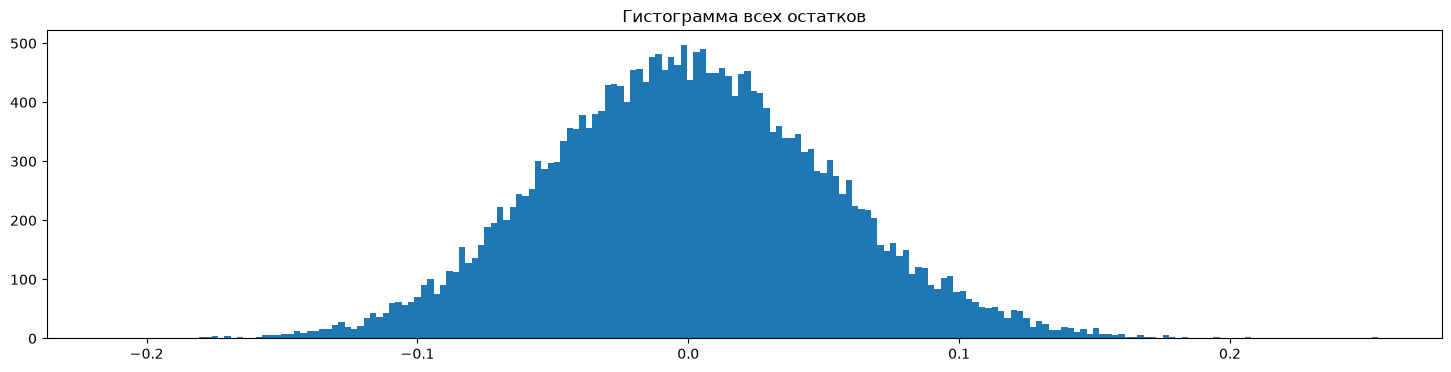

Стандартное отклонение логарифмических остатков: 0.053


In [10]:
residuals = np.log(train_df.pred) - np.log(train_df.num_sold)
plt.figure(figsize=(18, 4))
plt.scatter(np.arange(len(residuals)), residuals, s=1)
plt.title("Все остатки по номеру строки")
plt.ylabel("остаток")
plt.show()
plt.figure(figsize=(18, 4))
plt.hist(residuals, bins=200)
plt.title("Гистограмма всех остатков")
plt.show()
print(f"Стандартное отклонение логарифмических остатков: {residuals.std():.3f}")

Теперь посчитаем средний остаток для каждого из 366 дней года и поищем дни с необычно
большими остатками. Но что значит «необычно большой»? В статистических тестах обычно
берут уровень значимости 0.05. Однако уровень значимости — это доля ложных срабатываний,
а при проверке 366 дней хочется получить не больше одного ложного «праздника». При уровне
значимости 1/365 нужно искать остатки, превышающие три стандартных отклонения.

Чтобы одинаковые календарные дни разных лет попали в одну группу, используем «исправленный»
номер дня `dayfix`: в невисокосных годах начиная с марта сдвигаем номер дня на 1.

In [11]:
train_df["dayfix"] = train_df.date.dt.dayofyear
train_df.loc[(train_df.date.dt.year != 2016) & (train_df.date.dt.month >= 3), "dayfix"] += 1

print("Ищем остатки за пределами", norm.ppf([0.5 / 365, 364.5 / 365]))

rr = residuals.groupby(train_df.dayfix).mean()
rrstd = rr.std()
print(f"Стандартное отклонение при группировке по дню года: {rrstd:.5f}")
rrdf = pd.DataFrame(
    {
        "residual": rr,
        "z_score": rr / rrstd,
        "date": pd.date_range("2016-01-01", "2016-12-31"),
    }
)
rrdf[rrdf.z_score.abs() > 3]

Ищем остатки за пределами [-2.99552527  2.99552527]
Стандартное отклонение при группировке по дню года: 0.00602


,residual,z_score,date
dayfix,,,
295,-0.021971,-3.65236,2016-10-21


Таблица выше показывает одного кандидата в праздники: 21 октября. Но могут быть и праздники,
специфичные для отдельных стран. Если повторить ту же процедуру для остатков, сгруппированных
по стране и дню, появляются новые кандидаты:

In [12]:
# Кандидаты в праздники отдельных стран
rr = residuals.groupby([original_train_df.country, train_df.dayfix]).mean()
rrstd = rr.std()
print(f"Стандартное отклонение при группировке по стране и дню года: {rrstd:.5f}")
rrdf = pd.DataFrame(
    {
        "residual": rr,
        "z_score": rr / rrstd,
        "date": np.datetime64("2015-12-31")
        + pd.to_timedelta(rr.index.get_level_values(1), "D"),
    }
)
rrdf[rrdf.z_score.abs() > 3]

Стандартное отклонение при группировке по стране и дню года: 0.01104


residual   z_score       date
country dayfix                               
Finland 349    -0.033335 -3.018313 2016-12-14
Norway  41      0.034911  3.160997 2016-02-10
        93     -0.039099 -3.540243 2016-04-02
        94     -0.034916 -3.161440 2016-04-03
        98     -0.035003 -3.169307 2016-04-07
        139    -0.045526 -4.122114 2016-05-18
        148    -0.040626 -3.678477 2016-05-27
        151    -0.036815 -3.333374 2016-05-30
        330     0.035424  3.207459 2016-11-25
Sweden  96      0.043854  3.970758 2016-04-05

Признаки для этих праздников можно добавить самостоятельно — это хорошее упражнение.
Ещё одна открытая задача — поиск плавающих праздников (например, привязанных к первому
воскресенью ноября). Для них подходит тот же статистический тест, нужно только правильно
сгруппировать остатки.

# Обучение с валидацией

Для валидации используем `GroupKFold` с группировкой по году: на каждом фолде обучаемся
на трёх годах и проверяем модель на оставшемся. Для каждого фолда выводим:
- время обучения и SMAPE;
- диаграмму рассеяния y_true vs. y_pred для первого фолда (в идеале все точки лежат
  около диагонали).

Фолд 0 | 00:00 | SMAPE: 4.16877


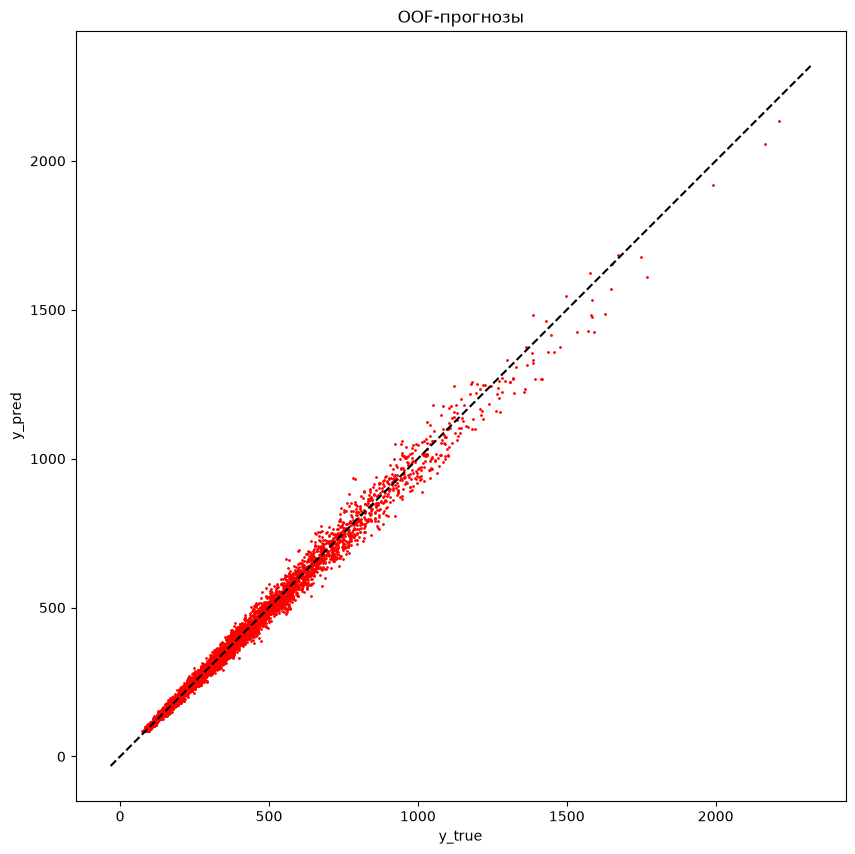

Фолд 1 | 00:00 | SMAPE: 4.34672
Фолд 2 | 00:00 | SMAPE: 4.42117


Фолд 3 | 00:00 | SMAPE: 4.40822
Средний SMAPE: 4.33622


In [13]:
oof = pd.Series(0.0, index=train_df.index)
score_list = []
kf = GroupKFold(n_splits=4)
for fold, (train_idx, val_idx) in enumerate(
    kf.split(train_df, groups=train_df.date.dt.year)
):
    X_tr = train_df.iloc[train_idx]
    X_va = train_df.iloc[val_idx]
    preproc, model = fit_model(X_tr, X_va, fold=fold)

print(f"Средний SMAPE: {sum(score_list) / len(score_list):.5f}")

# Прогноз на тесте

Обучаем модель на всех тренировочных данных и строим прогноз на тест. Сохраняем
два варианта:
- вещественные прогнозы регрессии (их удобно использовать для блендинга);
- прогнозы, округлённые до ближайшего целого (продажи — целые числа, и округление
  немного улучшает SMAPE).

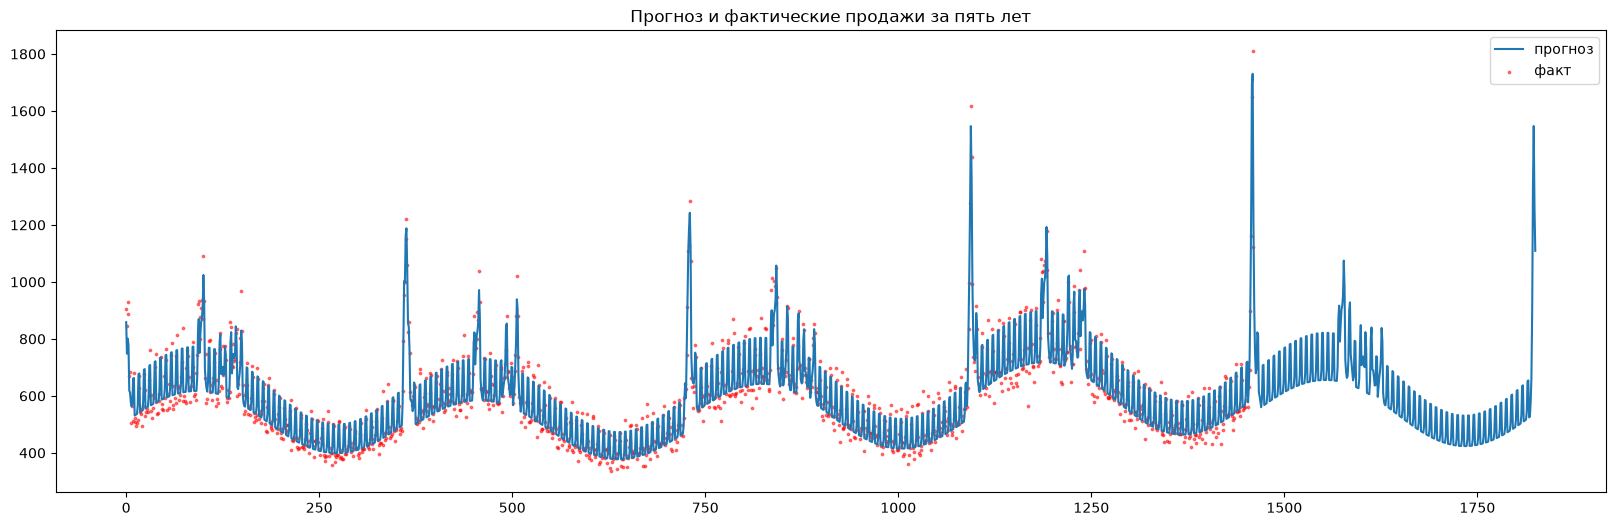

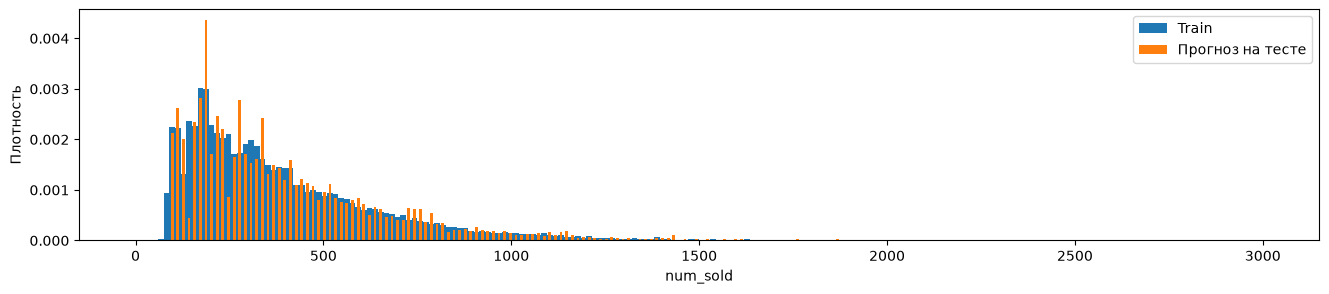

,row_id,num_sold
0,26298,385.477386
1,26299,597.187134
2,26300,170.425949
3,26301,672.169739
4,26302,1041.335571
...,...,...
6565,32863,802.881104
6566,32864,230.022934
6567,32865,907.185181
6568,32866,1400.011841


In [14]:
# Обучаем модель на всех тренировочных данных
preproc, model = fit_model(train_df)

plot_five_years_combination(engineer_more)  # быстрая проверка

# Прогноз на тесте
sub = original_test_df[["row_id"]].copy()
sub["num_sold"] = np.exp(model.predict(preproc.transform(test_df[features])))
sub.to_csv("submission_linear_model.csv", index=False)

# Распределение прогнозов на тесте в сравнении с тренировочными данными
plt.figure(figsize=(16, 3))
plt.hist(
    train_df["num_sold"], bins=np.linspace(0, 3000, 201), density=True, label="Train"
)
plt.hist(
    sub["num_sold"],
    bins=np.linspace(0, 3000, 201),
    density=True,
    rwidth=0.5,
    label="Прогноз на тесте",
)
plt.xlabel("num_sold")
plt.ylabel("Плотность")
plt.legend()
plt.show()

sub

In [15]:
# Округлённые прогнозы
sub_rounded = sub.copy()
sub_rounded["num_sold"] = sub_rounded["num_sold"].round()
sub_rounded.to_csv("submission_linear_model_rounded.csv", index=False)
sub_rounded

,row_id,num_sold
0,26298,385.0
1,26299,597.0
2,26300,170.0
3,26301,672.0
4,26302,1041.0
...,...,...
6565,32863,803.0
6566,32864,230.0
6567,32865,907.0
6568,32866,1400.0


# Важность признаков

Коэффициенты (веса) линейной модели показывают важность признаков. Начнём с весов дней
вокруг Пасхи и конца года:

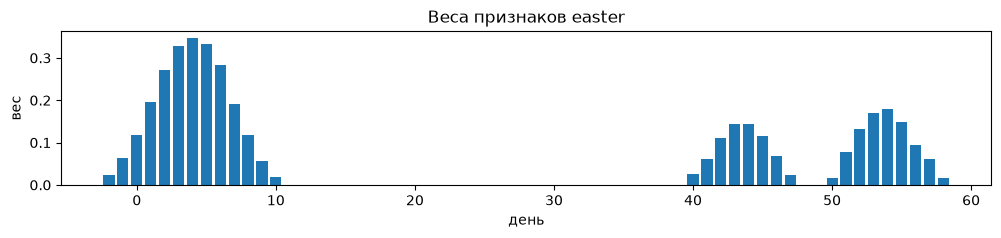

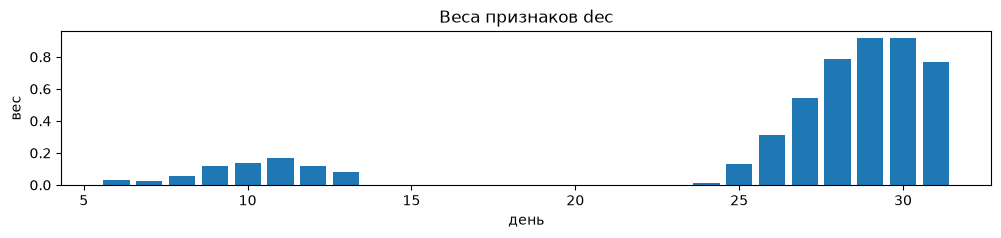

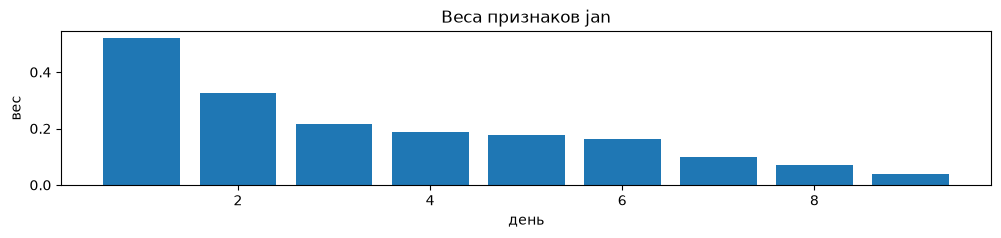

In [16]:
w = pd.Series(model.coef_, features)  # веса линейной регрессии
ws = w / preproc.scale_  # веса в масштабе исходных признаков (до StandardScaler)


def plot_feature_weights_numbered(prefix):
    prefix_features = [f for f in features if f.startswith(prefix)]
    plt.figure(figsize=(12, 2))
    plt.bar([int(f[len(prefix) :]) for f in prefix_features], ws[prefix_features])
    plt.title(f"Веса признаков {prefix}")
    plt.ylabel("вес")
    plt.xlabel("день")
    plt.show()


plot_feature_weights_numbered("easter")
plot_feature_weights_numbered("dec")
plot_feature_weights_numbered("jan")

Веса легко интерпретировать: например, если у признака выходного дня `wd56` вес $0.225$,
то продажи в выходные в $e^{0.225} = 1.25$ раза выше, чем в будни. А продажи 1 января
с весом $0.447$ в $e^{0.447} = 1.56$ раза выше, чем были бы без новогодних праздников.

Ниже — веса 30 самых важных признаков. Аналогично можно посмотреть на 30 наименее важных
и, возможно, часть из них удалить.

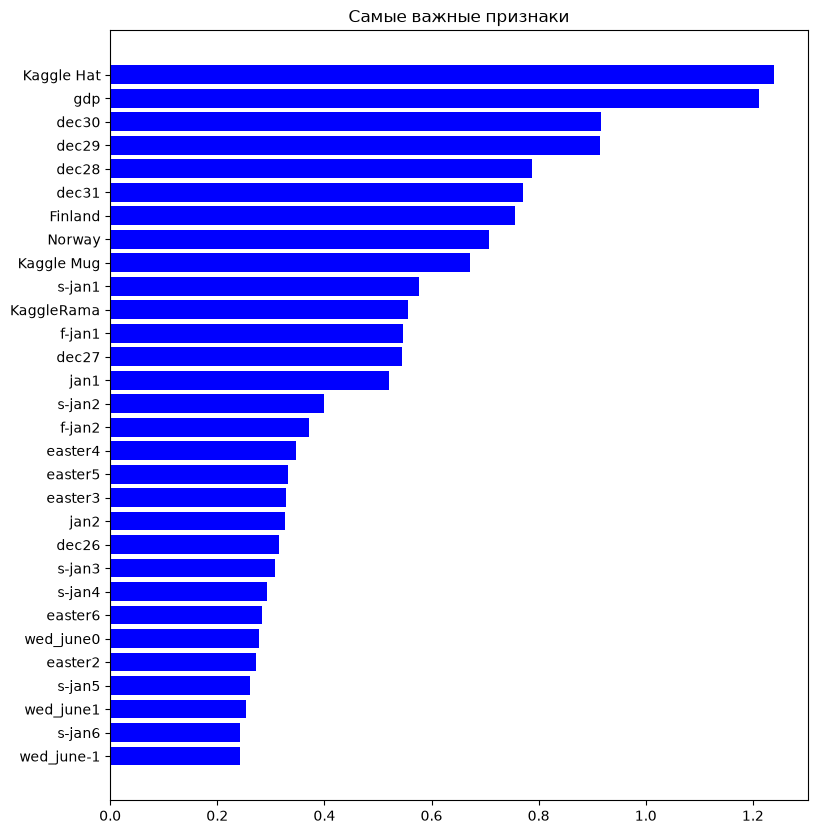

In [17]:
ws_sorted = ws.iloc[np.argsort(-np.abs(ws))]
ws_plot = ws_sorted.head(30)

plt.figure(figsize=(9, len(ws_plot) / 3))
plt.barh(
    np.arange(len(ws_plot)),
    ws_plot,
    color=ws_plot.apply(lambda ws: "b" if ws >= 0 else "y"),
)
plt.yticks(np.arange(len(ws_plot)), ws_plot.index)
plt.gca().invert_yaxis()
plt.title("Самые важные признаки")
plt.show()

# Показатель степени для ВВП

Вес признака ВВП (около 1.212) имеет особый смысл: так как и таргет, и признак взяты
под логарифм, продажи каждого года пропорциональны `GDP ** 1.212`. Этот показатель можно
использовать в других моделях — например, чтобы убрать годовой тренд перед обучением
бустинга, как в [LightGBM Quickstart](https://www.kaggle.com/ambrosm/tpsjan22-06-lightgbm-quickstart).

In [18]:
gdp_exponent = ws["gdp"]
gdp_exponent

1.212085571817878